In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/raw/Groceries_dataset.csv")

print("Dataset berhasil dibaca!")

Dataset berhasil dibaca!


In [2]:
df.head()

,Member_number,Date,itemDescription
0,1808,21-07-2015,tropical fruit
1,2552,05-01-2015,whole milk
2,2300,19-09-2015,pip fruit
3,1187,12-12-2015,other vegetables
4,3037,01-02-2015,whole milk


In [3]:
print("Jumlah baris dan kolom:", df.shape)
print("Jumlah variabel:", len(df.columns))
print("Nama variabel:", df.columns.tolist())

Jumlah baris dan kolom: (38765, 3)
Jumlah variabel: 3
Nama variabel: ['Member_number', 'Date', 'itemDescription']


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 38765 entries, 0 to 38764
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Member_number    38765 non-null  int64
 1   Date             38765 non-null  str  
 2   itemDescription  38765 non-null  str  
dtypes: int64(1), str(2)
memory usage: 908.7 KB


In [5]:
numerical = df.select_dtypes(include="number").columns.tolist()
categorical = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Variabel numerik:", numerical)
print("Jumlah variabel numerik:", len(numerical))

print("\nVariabel kategorikal:", categorical)
print("Jumlah variabel kategorikal:", len(categorical))

Variabel numerik: ['Member_number']
Jumlah variabel numerik: 1

Variabel kategorikal: ['Date', 'itemDescription']
Jumlah variabel kategorikal: 2


C:\Users\APIN\AppData\Local\Temp\ipykernel_10892\971715983.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


In [6]:
jumlah_duplikat = df.duplicated().sum()

print("Jumlah baris duplikat:", jumlah_duplikat)

Jumlah baris duplikat: 759


In [7]:
print("Jumlah null per variabel:")
print(df.isnull().sum())

print("\nTotal seluruh nilai null:", df.isnull().sum().sum())

Jumlah null per variabel:
Member_number      0
Date               0
itemDescription    0
dtype: int64

Total seluruh nilai null: 0


In [8]:
df.describe()

,Member_number
count,38765.000000
mean,3003.641868
std,1153.611031
min,1000.000000
25%,2002.000000
50%,3005.000000
75%,4007.000000
max,5000.000000


In [9]:
df.describe(include="object")

C:\Users\APIN\AppData\Local\Temp\ipykernel_10892\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,Date,itemDescription
count,38765,38765
unique,728,167
top,21-01-2015,whole milk
freq,96,2502


In [10]:
numerical = df.select_dtypes(include="number").columns.tolist()

categorical = df.select_dtypes(
    include=["str", "object", "category", "bool"]
).columns.tolist()

print("Numerik:", numerical, "| Jumlah:", len(numerical))
print("Kategorikal:", categorical, "| Jumlah:", len(categorical))

Numerik: ['Member_number'] | Jumlah: 1
Kategorikal: ['Date', 'itemDescription'] | Jumlah: 2


In [11]:
print("Null per kolom:")
print(df.isnull().sum())

print("\nTotal null:", df.isnull().sum().sum())

duplikat = df[df.duplicated(keep=False)].sort_values(
    ["Member_number", "Date", "itemDescription"]
)

display(duplikat.head(20))

df["Date"] = pd.to_datetime(
    df["Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

print("\nRentang tanggal:")
print("Tanggal awal:", df["Date"].min())
print("Tanggal akhir:", df["Date"].max())

print("\nTanggal yang gagal dikonversi:", df["Date"].isnull().sum())

Null per kolom:
Member_number      0
Date               0
itemDescription    0
dtype: int64

Total null: 0


,Member_number,Date,itemDescription
33098,1003,27-02-2014,rolls/buns
37649,1003,27-02-2014,rolls/buns
15099,1005,09-01-2014,rolls/buns
31248,1005,09-01-2014,rolls/buns
7532,1006,14-06-2015,frankfurter
8488,1006,14-06-2015,frankfurter
16100,1008,21-07-2015,yogurt
21210,1008,21-07-2015,yogurt
4769,1026,28-05-2015,root vegetables
20918,1026,28-05-2015,root vegetables



Rentang tanggal:
Tanggal awal: 2014-01-01 00:00:00
Tanggal akhir: 2015-12-30 00:00:00

Tanggal yang gagal dikonversi: 0


In [12]:
print("Jumlah duplikat:", df.duplicated().sum())

duplikat_asli = df[df.duplicated(keep=False)].sort_values(
    ["Member_number", "Date", "itemDescription"]
)

display(duplikat_asli.head(20))

print("\nTipe data terbaru:")
print(df.dtypes)

Jumlah duplikat: 759


,Member_number,Date,itemDescription
33098,1003,2014-02-27,rolls/buns
37649,1003,2014-02-27,rolls/buns
15099,1005,2014-01-09,rolls/buns
31248,1005,2014-01-09,rolls/buns
7532,1006,2015-06-14,frankfurter
8488,1006,2015-06-14,frankfurter
16100,1008,2015-07-21,yogurt
21210,1008,2015-07-21,yogurt
4769,1026,2015-05-28,root vegetables
20918,1026,2015-05-28,root vegetables



Tipe data terbaru:
Member_number               int64
Date               datetime64[us]
itemDescription               str
dtype: object


In [13]:
contoh_duplikat = df[df.duplicated(keep=False)]

print(contoh_duplikat.head(10).to_string(index=False))

print("\nJumlah duplikat:", df.duplicated().sum())

 Member_number       Date itemDescription
          1663 2015-02-07      rolls/buns
          3645 2015-12-12    citrus fruit
          3779 2015-09-15     frankfurter
          3812 2015-07-21         sausage
          1344 2015-09-04   bottled water
          2353 2015-05-02            soda
          4899 2015-03-12         chicken
          3929 2015-04-28 root vegetables
          3967 2015-11-23      whole milk
          2435 2015-07-17          onions

Jumlah duplikat: 759


In [14]:
frekuensi_barang = df["itemDescription"].value_counts()

print("10 barang paling sering tercatat:")
display(frekuensi_barang.head(10))

print("Jumlah jenis barang:", df["itemDescription"].nunique())

10 barang paling sering tercatat:


itemDescription
whole milk          2502
other vegetables    1898
rolls/buns          1716
soda                1514
yogurt              1334
root vegetables     1071
tropical fruit      1032
bottled water        933
sausage              924
citrus fruit         812
Name: count, dtype: int64

Jumlah jenis barang: 167


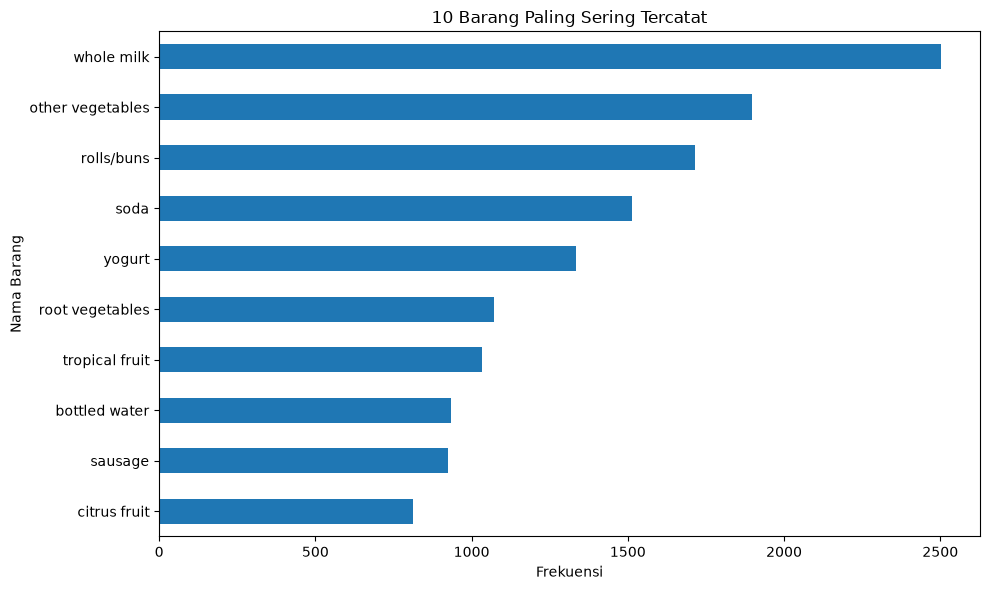

In [15]:
top_10 = df["itemDescription"].value_counts().head(10)

plt.figure(figsize=(10, 6))
top_10.sort_values().plot(kind="barh")

plt.title("10 Barang Paling Sering Tercatat")
plt.xlabel("Frekuensi")
plt.ylabel("Nama Barang")
plt.tight_layout()
plt.show()


In [16]:
df_clean = df.copy()

print("Jumlah baris sebelum pembersihan:", len(df_clean))

print("Jumlah baris duplikat:", df_clean.duplicated().sum())

df_tanpa_duplikat = df_clean.drop_duplicates()

print("Jumlah baris setelah duplikat dihapus:", len(df_tanpa_duplikat))
print("Jumlah baris yang akan dihapus:", len(df_clean) - len(df_tanpa_duplikat))

Jumlah baris sebelum pembersihan: 38765
Jumlah baris duplikat: 759
Jumlah baris setelah duplikat dihapus: 38006
Jumlah baris yang akan dihapus: 759


In [17]:
spasi_awal_akhir = (
    df["itemDescription"] != df["itemDescription"].str.strip()
).sum()


nama_normal = df["itemDescription"].str.strip().str.lower()

print("Nama barang dengan spasi berlebih:", spasi_awal_akhir)
print("Jumlah jenis barang sebelum normalisasi:",
      df["itemDescription"].nunique())
print("Jumlah jenis barang setelah normalisasi:",
      nama_normal.nunique())
      

Nama barang dengan spasi berlebih: 440
Jumlah jenis barang sebelum normalisasi: 167
Jumlah jenis barang setelah normalisasi: 167


In [18]:
df_clean = df.copy()


df_clean["itemDescription"] = (
    df_clean["itemDescription"]
    .str.strip()
    .str.lower()
)


print("Jumlah baris setelah perapian:", len(df_clean))
print("Jumlah nama barang unik:", df_clean["itemDescription"].nunique())
print(
    "Nama barang dengan spasi berlebih:",
    (df_clean["itemDescription"] != df_clean["itemDescription"].str.strip()).sum()
)

Jumlah baris setelah perapian: 38765
Jumlah nama barang unik: 167
Nama barang dengan spasi berlebih: 0


In [19]:
df_clean["Transaction"] = (
    df_clean["Member_number"].astype(str)
    + "_"
    + df_clean["Date"].dt.strftime("%Y-%m-%d")
)


print("Jumlah kelompok transaksi:", df_clean["Transaction"].nunique())

# Menampilkan contoh data
display(df_clean.head(10))

Jumlah kelompok transaksi: 14963


,Member_number,Date,itemDescription,Transaction
0,1808,2015-07-21,tropical fruit,1808_2015-07-21
1,2552,2015-01-05,whole milk,2552_2015-01-05
2,2300,2015-09-19,pip fruit,2300_2015-09-19
3,1187,2015-12-12,other vegetables,1187_2015-12-12
4,3037,2015-02-01,whole milk,3037_2015-02-01
5,4941,2015-02-14,rolls/buns,4941_2015-02-14
6,4501,2015-05-08,other vegetables,4501_2015-05-08
7,3803,2015-12-23,pot plants,3803_2015-12-23
8,2762,2015-03-20,whole milk,2762_2015-03-20
9,4119,2015-02-12,tropical fruit,4119_2015-02-12


In [20]:
basket = (
    df_clean
    .groupby(["Transaction", "itemDescription"])["itemDescription"]
    .count()
    .unstack(fill_value=0)
)


basket = basket > 0

print("Ukuran data keranjang belanja:", basket.shape)
print("\nContoh keranjang belanja:")
display(basket.head())

Ukuran data keranjang belanja: (14963, 167)

Contoh keranjang belanja:


itemDescription,abrasive cleaner,artif. sweetener,baby cosmetics,bags,baking powder,bathroom cleaner,beef,berries,beverages,bottled beer,...,uht-milk,vinegar,waffles,whipped/sour cream,whisky,white bread,white wine,whole milk,yogurt,zwieback
Transaction,,,,,,,,,,,,,,,,,,,,,
1000_2014-06-24,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
1000_2015-03-15,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,True,False
1000_2015-05-27,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1000_2015-07-24,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1000_2015-11-25,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [21]:
try:
    from mlxtend.frequent_patterns import apriori, association_rules
    print("Pustaka mlxtend berhasil diimpor.")
except ImportError:
    print("Pustaka mlxtend belum terpasang.")

Pustaka mlxtend berhasil diimpor.


In [22]:
frequent_items = apriori(
    basket,
    min_support=0.01,
    use_colnames=True
)


frequent_items = frequent_items.sort_values(
    by="support",
    ascending=False
)

print("Jumlah kombinasi barang yang ditemukan:", len(frequent_items))
display(frequent_items.head(10))

Jumlah kombinasi barang yang ditemukan: 69


,support,itemsets
62,0.157923,frozenset({whole milk})
39,0.122101,frozenset({other vegetables})
45,0.110005,frozenset({rolls/buns})
51,0.097106,frozenset({soda})
63,0.085879,frozenset({yogurt})
46,0.069572,frozenset({root vegetables})
56,0.067767,frozenset({tropical fruit})
4,0.060683,frozenset({bottled water})
48,0.060349,frozenset({sausage})
14,0.053131,frozenset({citrus fruit})


In [23]:
rules = association_rules(
    frequent_items,
    metric="confidence",
    min_threshold=0.2
)


rules = rules.sort_values(
    by="lift",
    ascending=False
)

print("Jumlah aturan asosiasi:", len(rules))


display(
    rules[
        ["antecedents", "consequents", "support", "confidence", "lift"]
    ].head(10)
)

Jumlah aturan asosiasi: 0


,antecedents,consequents,support,confidence,lift


In [24]:
frequent_items = apriori(
    basket,
    min_support=0.005,
    use_colnames=True
)

print("Jumlah kombinasi barang:", len(frequent_items))


rules = association_rules(
    frequent_items,
    metric="confidence",
    min_threshold=0.1
)

print("Jumlah aturan asosiasi:", len(rules))


if len(rules) > 0:
    rules = rules.sort_values(by="lift", ascending=False)

    display(
        rules[
            ["antecedents", "consequents", "support", "confidence", "lift"]
        ].head(10)
    )
else:
    print("Belum ada aturan asosiasi yang terbentuk.")

Jumlah kombinasi barang: 126
Jumlah aturan asosiasi: 19


,antecedents,consequents,support,confidence,lift
5,frozenset({frankfurter}),frozenset({other vegetables}),0.005146,0.136283,1.116150
0,frozenset({bottled beer}),frozenset({whole milk}),0.007151,0.157817,0.999330
14,frozenset({sausage}),frozenset({whole milk}),0.008955,0.148394,0.939663
7,frozenset({newspapers}),frozenset({whole milk}),0.005614,0.144330,0.913926
4,frozenset({domestic eggs}),frozenset({whole milk}),0.005280,0.142342,0.901341
6,frozenset({frankfurter}),frozenset({whole milk}),0.005280,0.139823,0.885388
11,frozenset({pork}),frozenset({whole milk}),0.005012,0.135135,0.855703
10,frozenset({pip fruit}),frozenset({whole milk}),0.006616,0.134877,0.854071
3,frozenset({citrus fruit}),frozenset({whole milk}),0.007151,0.134591,0.852259
15,frozenset({shopping bags}),frozenset({whole milk}),0.006349,0.133427,0.844887


In [25]:
hasil_rules = rules[
    ["antecedents", "consequents", "support", "confidence", "lift"]
].copy()


hasil_rules["antecedents"] = hasil_rules["antecedents"].apply(
    lambda x: ", ".join(sorted(x))
)
hasil_rules["consequents"] = hasil_rules["consequents"].apply(
    lambda x: ", ".join(sorted(x))
)


hasil_rules = hasil_rules.sort_values(by="lift", ascending=False)

display(hasil_rules)

,antecedents,consequents,support,confidence,lift
5,frankfurter,other vegetables,0.005146,0.136283,1.116150
0,bottled beer,whole milk,0.007151,0.157817,0.999330
14,sausage,whole milk,0.008955,0.148394,0.939663
7,newspapers,whole milk,0.005614,0.144330,0.913926
4,domestic eggs,whole milk,0.005280,0.142342,0.901341
6,frankfurter,whole milk,0.005280,0.139823,0.885388
11,pork,whole milk,0.005012,0.135135,0.855703
10,pip fruit,whole milk,0.006616,0.134877,0.854071
3,citrus fruit,whole milk,0.007151,0.134591,0.852259
15,shopping bags,whole milk,0.006349,0.133427,0.844887


In [26]:
jumlah_barang_per_transaksi = df_clean.groupby("Transaction")[
    "itemDescription"
].nunique()

print("Statistik jumlah barang per transaksi:")
print(jumlah_barang_per_transaksi.describe())

print(
    "\nTransaksi dengan lebih dari satu jenis barang:",
    (jumlah_barang_per_transaksi > 1).sum()
)

Statistik jumlah barang per transaksi:
count    14963.000000
mean         2.539999
std          1.060993
min          1.000000
25%          2.000000
50%          2.000000
75%          3.000000
max         10.000000
Name: itemDescription, dtype: float64

Transaksi dengan lebih dari satu jenis barang: 14758


In [27]:
hasil_rules.to_csv(
    "hasil_aturan_asosiasi.csv",
    index=False
)

frequent_items.to_csv(
    "hasil_kombinasi_barang.csv",
    index=False
)

print("Hasil analisis berhasil disimpan.")

Hasil analisis berhasil disimpan.


In [28]:
evaluasi = hasil_rules.sort_values(
    by="lift",
    ascending=False
).head(3).copy()

evaluasi["support (%)"] = evaluasi["support"] * 100
evaluasi["confidence (%)"] = evaluasi["confidence"] * 100

display(
    evaluasi[
        [
            "antecedents",
            "consequents",
            "support (%)",
            "confidence (%)",
            "lift"
        ]
    ].round(3)
)


print(
    "Aturan dengan lift > 1:",
    (hasil_rules["lift"] > 1).sum()
)
print(
    "Total aturan:",
    len(hasil_rules)
)

,antecedents,consequents,support (%),confidence (%),lift
5,frankfurter,other vegetables,0.515,13.628,1.116
0,bottled beer,whole milk,0.715,15.782,0.999
14,sausage,whole milk,0.896,14.839,0.940


Aturan dengan lift > 1: 1
Total aturan: 19
